# MNIST ile MLP Tabanlı El Yazısı Rakam Tanıma

## 1. Projenin Amacı

Bu projede, MNIST el yazısı rakam veri seti kullanılarak Multi-Layer Perceptron (MLP) tabanlı bir sınıflandırma modeli geliştirilmiştir. Amaç, 0–9 arasındaki el yazısı rakamlarını sınıflandırmak ve farklı MLP mimarilerinin performanslarını karşılaştırmaktır.

Proje kapsamında PyTorch kullanılmış, model sıfırdan eğitilmiş ve CNN mimarisi kullanılmamıştır.

## 2. Kullanılan Yöntem

- **Veri seti:** MNIST
- **Görüntü boyutu:** 28 × 28 piksel
- **Sınıf sayısı:** 10
- **Model:** Multi-Layer Perceptron (MLP)
- **Aktivasyon fonksiyonu:** ReLU
- **Kayıp fonksiyonu:** Cross-Entropy Loss
- **Optimizer:** Adam
- **Batch size:** 64
- **Epoch sayısı:** 5
- **Öğrenme oranı:** 0.001

Model performansı train, validation ve test veri kümeleri üzerinden değerlendirilmiştir.

## 3. Kütüphanelerin İçe Aktarılması ve Deney Ayarları

Bu bölümde veri işleme, model oluşturma, eğitim ve görselleştirme için gerekli Python kütüphaneleri içe aktarılmaktadır.

- **PyTorch:** Sinir ağını oluşturmak ve eğitmek için kullanılmıştır.
- **Torchvision:** MNIST veri setini yüklemek ve görüntü dönüşümlerini uygulamak için kullanılmıştır.
- **NumPy:** Sayısal işlemler için kullanılmıştır.
- **Matplotlib:** Eğitim sonuçlarını grafiklerle göstermek için kullanılmıştır.
- **Time:** Eğitim süresini ölçmek için kullanılmıştır.

Deneylerde aynı veri ayrımını ve karşılaştırılabilir eğitim ayarlarını kullanmak, farklı model mimarilerinin sonuçlarını değerlendirmeyi kolaylaştırmaktadır.

In [105]:
# Kütüphanelerin importu
import time
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

In [106]:

# Kullanılabilir işlem birimini belirle
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Seçilen cihaz:", device)


Seçilen cihaz: cpu


## 4. MNIST Veri Setinin Yüklenmesi

Bu çalışmada, el yazısı rakamların sınıflandırılması için MNIST veri seti kullanılmıştır. Veri seti, 0 ile 9 arasındaki rakamlara ait 28 × 28 piksel boyutunda gri tonlamalı görüntülerden oluşmaktadır.

PyTorch'un `torchvision.datasets.MNIST` arayüzü kullanılarak eğitim ve test veri kümeleri yüklenmiştir. `download=True` parametresi, veri seti çalışma ortamında mevcut değilse indirilmesini sağlar.

Görüntülere `transforms.ToTensor()` dönüşümü uygulanmıştır. Bu dönüşüm, görüntüleri PyTorch tensörlerine çevirir ve piksel değerlerini 0–1 aralığına getirir.

MNIST'in 60.000 görüntülük eğitim bölümü modelin eğitimi ve validation ayrımı için, 10.000 görüntülük test bölümü ise nihai performans değerlendirmesi için kullanılacaktır.

In [107]:

# MNIST veri setini yükleme
transform = transforms.ToTensor()

# train verisi: Modelin eğitileceği veri
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# test verisi: Modelin başarısını ölçmek üzere test edileceği veri
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("train veri sayısı:", len(train_dataset))
print("test veri sayısı:", len(test_dataset))


train veri sayısı: 60000
test veri sayısı: 10000


## 5. Veri Setinin Görselleştirilmesi

Modeli eğitmeden önce veri setindeki örnek görüntüler incelenmiştir. Bu adım, görüntülerin boyutunu, renk yapısını ve etiketlerini kontrol etmek amacıyla gerçekleştirilmiştir.

MNIST görüntüleri siyah arka plan üzerinde açık renkli rakamlardan oluşmaktadır. Her görüntüye, temsil ettiği rakamı gösteren bir etiket eşlik eder.

Görselleştirme sayesinde verinin beklenen formatta yüklendiği kontrol edilmiştir.

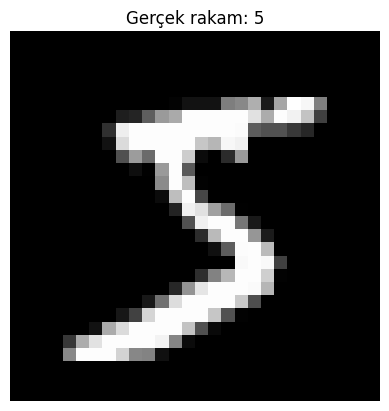

In [108]:

# Veri setindeki ilk görüntüyü al
image, label = train_dataset[0]

# Görüntüyü çiz
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Gerçek rakam: {label}") # başlık
plt.axis("off") # eksenleri görünür yapma
plt.show()


## 6. Eğitim, Validation ve Test Veri Kümeleri

Modelin performansını doğru değerlendirmek amacıyla veri kümeleri üç bölüme ayrılmıştır.

- **Train:** 54.000 görüntü. Modelin öğrenilebilir parametrelerini güncellemek için kullanılır.
- **Validation:** 6.000 görüntü. Eğitim sürecinde modelin performansını izlemek ve farklı yapılandırmaları karşılaştırmak için kullanılır.
- **Test:** 10.000 görüntü. Modelin nihai performansını değerlendirmek için kullanılır.

MNIST'in 60.000 görüntülük eğitim bölümü, sabit bir rastgelelik tohumu kullanılarak %90 train ve %10 validation şeklinde ayrılmıştır. Ayrı test kümesi eğitim ve model seçimi sürecinden bağımsız tutulmuştur.

Bu ayrım, modelin yalnızca eğitim örneklerinde değil, daha önce görmediği örneklerde de ne kadar başarılı olduğunu değerlendirmeyi sağlar.

In [109]:
# Toplam 60.000 eğitim görüntüsünü 54.000 + 6.000 olarak ayıracağız. MNIST'in ayrı 10.000 görüntülük test kümesini değiştirmeyeceğiz.
# Eğitim verisinin %10'unu validation için ayırıyoruz.

train_size = 54000
val_size = 6000

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

print("Train örnek sayısı:", len(train_subset))
print("Validation örnek sayısı:", len(val_subset))
print("Test örnek sayısı:", len(test_dataset))


Train örnek sayısı: 54000
Validation örnek sayısı: 6000
Test örnek sayısı: 10000


## 7. Verilerin Batch'ler Halinde İşlenmesi

PyTorch `DataLoader` sınıfı, veri örneklerini modelin işleyeceği küçük gruplar hâlinde sunmak için kullanılmıştır.

Bu çalışmada batch size değeri 64 olarak belirlenmiştir. Eğitim sırasında `shuffle=True` kullanılarak örneklerin sırası her epoch'ta karıştırılır. Validation ve test aşamalarında ise `shuffle=False` kullanılmıştır.

Batch'ler hâlinde işlem yapmak, eğitim verisinin kontrollü biçimde işlenmesini sağlar ve gradyan hesaplamalarının her grup üzerinden gerçekleştirilmesine olanak tanır.

In [110]:
# DataLoader oluşturma: Veriyi ayırmak tek başına yeterli değil. Modelimize verileri küçük gruplar, yani batch'ler halinde sunacağız.

BATCH_SIZE = 64

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Bir batch'in yapısını kontrol edelim
images, labels = next(iter(train_loader)) # Bu kullanım indeksle erişilemeyen iterable'ların ilk elemanına ulaşmak için kulanılır

print("Batch görüntü boyutu:", images.shape)
print("Batch etiket boyutu:", labels.shape)
print("İlk 10 etiket:", labels[:10].tolist())


Batch görüntü boyutu: torch.Size([64, 1, 28, 28])
Batch etiket boyutu: torch.Size([64])
İlk 10 etiket: [6, 5, 2, 3, 4, 9, 8, 2, 4, 3]


## 8. Temel MLP Modelinin Oluşturulması

Bu deneyde, MNIST görüntülerini sınıflandırmak amacıyla Multi-Layer Perceptron (MLP) mimarisi kullanılmıştır. CNN kullanılmamış ve model sıfırdan oluşturulmuştur.

28 × 28 boyutundaki her görüntü, Flatten katmanı aracılığıyla 784 özellikli bir vektöre dönüştürülür. Modelin gizli katmanları sırasıyla 256 ve 128 nörondan oluşur. Bu katmanlarda ReLU aktivasyon fonksiyonu kullanılmıştır.

Son katmanda 10 çıktı üretilerek 0–9 arasındaki rakam sınıfları temsil edilir. Modelin öğrenilebilir parametre sayısı 235.146'dır.

Bu mimari, ödevde istenen en az iki gizli katman ve ReLU aktivasyonu koşullarını karşılamaktadır.

In [111]:
# PyTorch ile modeli yazalım

class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        # Gizli katmanlar ve çıkış katmanı
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


# Modeli oluştur ve uygun cihaza gönder
model = MLP().to(device)

print(model)


MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [112]:
# Modelin boyutlarını kontrol edelim: Modeli eğitmeden önce ileri geçişin doğru çalıştığını doğrulayalım.

# Bir batch al
images, labels = next(iter(train_loader))

# Modelin tahmin skorlarını üret
images = images.to(device)
outputs = model(images)

print("Girdi boyutu:", images.shape)
print("Çıktı boyutu:", outputs.shape)
print("İlk görüntü için 10 sınıf skoru:")
print(outputs[0].detach().cpu())


Girdi boyutu: torch.Size([64, 1, 28, 28])
Çıktı boyutu: torch.Size([64, 10])
İlk görüntü için 10 sınıf skoru:
tensor([ 0.0782, -0.1072,  0.0156,  0.0243,  0.0033, -0.0045,  0.0974, -0.0496,
         0.0315, -0.1235])


In [113]:
# Öğrenilebilir parametreleri inceleyelim
total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Öğrenilebilir parametre sayısı:", total_params)


Öğrenilebilir parametre sayısı: 235146


In [114]:
model = MLP().to(device)

images, labels = next(iter(train_loader))
images = images.to(device)

outputs = model(images)

print("Cihaz:", device)
print("Girdi boyutu:", images.shape)
print("Çıktı boyutu:", outputs.shape)

total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Öğrenilebilir parametre sayısı:", total_params)


Cihaz: cpu
Girdi boyutu: torch.Size([64, 1, 28, 28])
Çıktı boyutu: torch.Size([64, 10])
Öğrenilebilir parametre sayısı: 235146


In [115]:
# Loss fonksiyonunu oluştur
criterion = nn.CrossEntropyLoss()

# Eğitim verisinden bir batch al
images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)

# Modelin tahminlerini üret
outputs = model(images)

# Tahminler ile gerçek etiketleri karşılaştır
loss = criterion(outputs, labels)

print("Loss:", loss.item())
print("Tahmin edilen ilk rakam:", outputs[0].argmax().item())
print("Gerçek ilk rakam:", labels[0].item())


Loss: 2.3073155879974365
Tahmin edilen ilk rakam: 5
Gerçek ilk rakam: 9


In [116]:

# Loss ve optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Bir batch al
images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)

# 1. Eski gradyanları temizle
optimizer.zero_grad()

# 2. Tahmin üret
outputs = model(images)

# 3. Loss hesapla
loss = criterion(outputs, labels)

# 4. Gradyanları hesapla
loss.backward()

# 5. Ağırlıkları güncelle
optimizer.step()

print("Bir güncelleme tamamlandı.")
print("Batch loss:", loss.item())


Bir güncelleme tamamlandı.
Batch loss: 2.315823793411255


## 9. Deney 1: Temel MLP Modelinin Eğitilmesi

Bu bölümde, iki gizli katmana sahip MLP modeli eğitilmiştir. Modelin gizli katmanlarında ReLU aktivasyon fonksiyonu kullanılmıştır. Kayıp fonksiyonu olarak Cross Entropy, optimizasyon yöntemi olarak Adam seçilmiştir.

- **Gizli katmanlar:** 256 ve 128 nöron
- **Öğrenme oranı:** 0.001
- **Batch boyutu:** 64
- **Epoch sayısı:** 5

Her epoch sonunda eğitim ve doğrulama (validation) kaybı ile doğruluğu hesaplanarak sonuçlar kaydedilmiştir.

In [117]:

# Modeli sıfırdan oluştur
torch.manual_seed(42)
model = MLP().to(device)

# Kayıp fonksiyonu ve optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 5

# Sonuçları kaydetmek için
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

start_time = time.time()

for epoch in range(EPOCHS):

    # ---- TRAIN ----
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # ---- VALIDATION ----
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    # Sonuçları sakla
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

training_time = time.time() - start_time

print(f"\nToplam eğitim süresi: {training_time:.2f} saniye")


Epoch 1/5 | Train Loss: 0.3083 | Train Acc: 90.99% | Val Loss: 0.1740 | Val Acc: 94.95%
Epoch 2/5 | Train Loss: 0.1175 | Train Acc: 96.47% | Val Loss: 0.1119 | Val Acc: 96.65%
Epoch 3/5 | Train Loss: 0.0769 | Train Acc: 97.56% | Val Loss: 0.0939 | Val Acc: 97.32%
Epoch 4/5 | Train Loss: 0.0532 | Train Acc: 98.33% | Val Loss: 0.0813 | Val Acc: 97.32%
Epoch 5/5 | Train Loss: 0.0406 | Train Acc: 98.67% | Val Loss: 0.0865 | Val Acc: 97.50%

Toplam eğitim süresi: 57.76 saniye


## 10. Eğitim ve Validation Sonuçları

Eğitim sürecindeki değişimleri incelemek amacıyla train ve validation loss değerleri ile train ve validation accuracy değerleri epoch bazında görselleştirilmiştir.

Loss grafiklerinde düşük değerler, model tahminlerinin gerçek etiketlerle daha uyumlu olduğunu gösterir. Accuracy grafiklerinde ise yüksek değerler daha fazla örneğin doğru sınıflandırıldığını ifade eder.

Train ve validation sonuçlarının birlikte incelenmesi, modelin eğitim verisini öğrenme düzeyini ve daha önce görmediği validation örneklerine ne ölçüde genelleme yaptığını değerlendirmeyi sağlar.

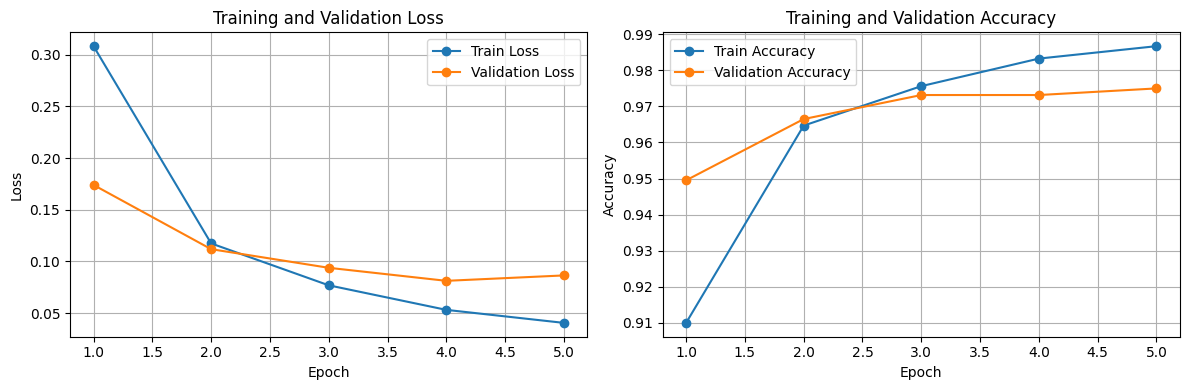

Test Loss: 0.0802
Test Accuracy: 97.53%
Eğitim süresi: 57.76 saniye


In [118]:
# Eğitim grafiklerini çiz
epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_acc"], marker="o", label="Train Accuracy")
plt.plot(epochs, history["val_acc"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# Test kümesinde nihai değerlendirme
model.eval()
test_correct = 0
test_total = 0
test_loss = 0.0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * labels.size(0)
        predictions = outputs.argmax(dim=1)

        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

test_loss /= test_total
test_accuracy = test_correct / test_total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")
print(f"Eğitim süresi: {training_time:.2f} saniye")


## 11. Test Performansı

Modelin nihai performansı, eğitim ve model seçimi aşamalarında kullanılmayan MNIST test kümesi üzerinde değerlendirilmiştir.

Test loss ve test accuracy değerleri hesaplanarak modelin daha önce görmediği örneklerdeki sınıflandırma başarısı ölçülmüştür. Test kümesi, model eğitimi ve hiperparametre seçimi için kullanılmamıştır.

Elde edilen test sonuçları, validation sonuçlarıyla birlikte ele alınarak modelin genelleme performansını değerlendirmek amacıyla kullanılmıştır.

## 12. Deney 2: Daha Küçük MLP Modeli

İlk modelle karşılaştırmak amacıyla daha az nöron içeren ikinci bir MLP modeli oluşturulmuştur. Bu modelin gizli katmanlarında sırasıyla 128 ve 64 nöron bulunmaktadır.

Her iki deneyde de aynı veri kümeleri, Adam optimizer, öğrenme oranı ve epoch sayısı kullanılmıştır. Böylece model boyutunun doğruluk ve eğitim süresi üzerindeki etkisi karşılaştırılabilmiştir.

In [119]:
# İkinci deney: Daha küçük MLP

class MLP_Small(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


# Eğitim fonksiyonu
def train_experiment(model, epochs=5):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    results = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": []
    }

    start = time.time()

    for epoch in range(epochs):
        model.train()
        loss_sum = correct = total = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()

            loss_sum += loss.item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)

        results["train_loss"].append(loss_sum / total)
        results["train_acc"].append(correct / total)

        model.eval()
        loss_sum = correct = total = 0

        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                out = model(x)
                loss = criterion(out, y)

                loss_sum += loss.item() * y.size(0)
                correct += (out.argmax(1) == y).sum().item()
                total += y.size(0)

        results["val_loss"].append(loss_sum / total)
        results["val_acc"].append(correct / total)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Acc: {results['train_acc'][-1]:.2%} | "
            f"Val Acc: {results['val_acc'][-1]:.2%}"
        )

    elapsed = time.time() - start
    return model, results, elapsed


torch.manual_seed(42)
small_model, small_history, small_time = train_experiment(
    MLP_Small(), epochs=5
)

print(f"\nİkinci deney eğitim süresi: {small_time:.2f} saniye")


Epoch 1/5 | Train Acc: 90.14% | Val Acc: 93.83%
Epoch 2/5 | Train Acc: 95.60% | Val Acc: 95.38%
Epoch 3/5 | Train Acc: 96.82% | Val Acc: 96.38%
Epoch 4/5 | Train Acc: 97.60% | Val Acc: 96.78%
Epoch 5/5 | Train Acc: 98.04% | Val Acc: 96.87%

İkinci deney eğitim süresi: 49.29 saniye


## 13. Deney Sonuçlarının Karşılaştırılması

İki modelin son epoch sonuçları ve eğitim süreleri karşılaştırılmıştır. Karşılaştırmada train accuracy, validation accuracy, loss değerleri ve eğitim süresi dikkate alınmıştır. Validation başarısı, modellerin daha önce eğitim sırasında kullanılmayan örneklerdeki performansını değerlendirmek için temel ölçüt olarak ele alınmıştır.

In [120]:

import pandas as pd

comparison = pd.DataFrame({
    "Metrik": [
        "Train Accuracy",
        "Validation Accuracy",
        "Train Loss",
        "Validation Loss",
        "Eğitim Süresi (sn)"
    ],
    "Deney 1 (256, 128)": [
        history["train_acc"][-1],
        history["val_acc"][-1],
        history["train_loss"][-1],
        history["val_loss"][-1],
        training_time
    ],
    "Deney 2 (128, 64)": [
        small_history["train_acc"][-1],
        small_history["val_acc"][-1],
        small_history["train_loss"][-1],
        small_history["val_loss"][-1],
        small_time
    ]
})

print(comparison.to_string(index=False))


             Metrik  Deney 1 (256, 128)  Deney 2 (128, 64)
     Train Accuracy            0.986722           0.980352
Validation Accuracy            0.975000           0.968667
         Train Loss            0.040561           0.063713
    Validation Loss            0.086485           0.107058
 Eğitim Süresi (sn)           57.761595          49.287243


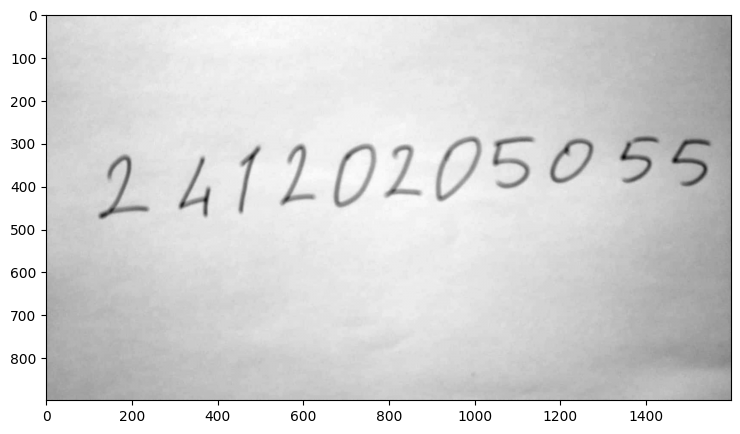

Fotoğraf boyutu: (1599, 899)


In [121]:

from PIL import Image
import matplotlib.pyplot as plt

img = Image.open("foto.jpg").convert("L")

plt.figure(figsize=(14, 5))
plt.imshow(img, cmap="gray")
plt.axis("on")
plt.show()

print("Fotoğraf boyutu:", img.size)


Saving foto.jpg to foto (4).jpg
Bulunan parça sayısı: 11


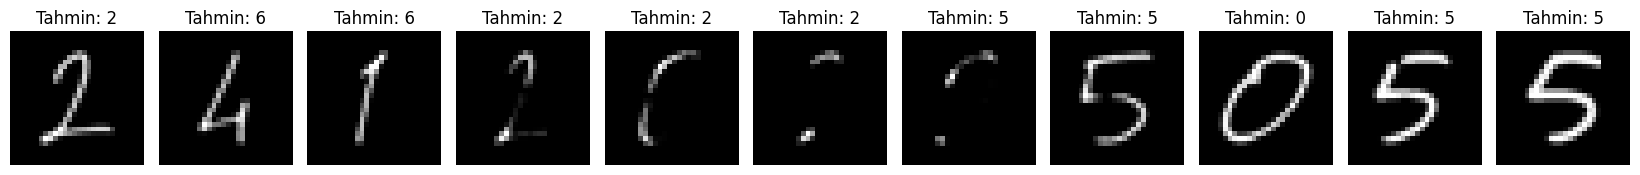

Model tahmini: 26622255055


In [122]:

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import torch

# Fotoğrafı yükle
uploaded = files.upload()
img = Image.open(next(iter(uploaded))).convert("L")

# Rakamların olduğu bölge
region = img.crop((100, 270, 1550, 480))
arr = np.array(region)

# Koyu kalem izlerini beyaz, kâğıdı siyah yap
mask = arr < 125

# Çok küçük gürültüleri temizle
mask[:3, :] = False
mask[-3:, :] = False

# Rakamların bulunduğu sütunları belirle
active = mask.sum(axis=0) >= 2

# Sütun aralıklarını bul
segments = []
start = None

for i, val in enumerate(active):
    if val and start is None:
        start = i
    elif not val and start is not None:
        if i - start >= 2:
            segments.append((start, i))
        start = None

if start is not None:
    segments.append((start, len(active)))

# Yakın parçaları birleştir
merged = []
for a, b in segments:
    if merged and a - merged[-1][1] <= 15:
        merged[-1] = (merged[-1][0], b)
    else:
        merged.append((a, b))

print("Bulunan parça sayısı:", len(merged))

def prepare_digit(segment):
    a, b = segment
    submask = mask[:, max(0, a-4):min(mask.shape[1], b+4)]

    ys, xs = np.where(submask)
    if len(xs) == 0:
        raise ValueError("Rakam bulunamadı.")

    submask = submask[
        max(0, ys.min()-4):min(submask.shape[0], ys.max()+5),
        max(0, xs.min()-4):min(submask.shape[1], xs.max()+5)
    ]

    # Siyah zemin, beyaz rakam
    digit_img = Image.fromarray((submask * 255).astype(np.uint8))
    digit_img.thumbnail((20, 20))

    canvas = Image.new("L", (28, 28), 0)
    canvas.paste(
        digit_img,
        ((28-digit_img.width)//2, (28-digit_img.height)//2)
    )

    arr = np.array(canvas, dtype=np.float32) / 255.0
    return torch.tensor(arr).unsqueeze(0).unsqueeze(0)

# Tahminler
model.eval()
predictions = []
digit_images = []

with torch.no_grad():
    for segment in merged:
        digit = prepare_digit(segment).to(device)
        pred = model(digit).argmax(dim=1).item()
        predictions.append(pred)
        digit_images.append(digit.squeeze().cpu().numpy())

# Görselleri kontrol et
if digit_images:
    fig, axes = plt.subplots(
        1, len(digit_images),
        figsize=(max(12, len(digit_images)*1.5), 3)
    )
    if len(digit_images) == 1:
        axes = [axes]

    for ax, digit_img, pred in zip(axes, digit_images, predictions):
        ax.imshow(digit_img, cmap="gray")
        ax.set_title(f"Tahmin: {pred}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

print("Model tahmini:", "".join(map(str, predictions)))


In [123]:

gercek_rakamlar = [int(r) for r in "24120205055"]

dogru_sayisi = sum(
    tahmin == gercek
    for tahmin, gercek in zip(predictions, gercek_rakamlar)
)

print("Gerçek numara:  ", "".join(map(str, gercek_rakamlar)))
print("Model tahmini:  ", "".join(map(str, predictions)))
print(f"Doğru tahmin: {dogru_sayisi}/{len(gercek_rakamlar)}")
print(f"El yazısı doğruluğu: %{100 * dogru_sayisi / len(gercek_rakamlar):.2f}")


Gerçek numara:   24120205055
Model tahmini:   26622255055
Doğru tahmin: 7/11
El yazısı doğruluğu: %63.64


## 14. Genel Değerlendirme ve Sonuç

Bu çalışmada, MNIST veri setindeki el yazısı rakamlarını sınıflandırmak için iki farklı MLP mimarisi eğitilmiştir. İlk model 256 ve 128, ikinci model ise 128 ve 64 nöron içeren iki gizli katmana sahiptir.

İlk model %97,50 validation doğruluğu ve %97,53 test doğruluğu elde etmiştir. İkinci modelin validation doğruluğu %96,87'dir. Sonuçlar, ilk modelin bu deneylerde daha yüksek sınıflandırma başarısı sağladığını; küçük modelin ise daha kısa sürede eğitildiğini göstermektedir.

Eğitim ve validation sonuçlarının birlikte incelenmesi, modellerin genelleme performansını değerlendirmeye yardımcı olmuştur. Sonuç olarak MLP, CNN kullanılmadan da MNIST rakamlarını yüksek doğrulukla sınıflandırabilmiştir.

### Kendi El Yazım Üzerinde Deneme

Eğitilen MLP modeli, kendi el yazımla yazdığım 24120205055 numarasının rakamları üzerinde test edilmiştir. Görüntüdeki rakamlar ayrı ayrı kesilmiş, 28×28 piksel boyutuna dönüştürülmüş ve modele verilmiştir.

Model, 11 rakamın 7 tanesini doğru tahmin etmiş ve bu örnekte %63,64 doğruluk elde etmiştir. Bu sonuç, MNIST test kümesindeki %97,53 doğruluktan düşüktür.

Aradaki fark; el yazısının MNIST örneklerinden farklı olması, fotoğrafın ışık ve arka plan koşulları ve görüntü ön işleme adımlarından kaynaklanabilir. Bu deney, modelin test kümesindeki başarısının farklı gerçek dünya örneklerinde aynı düzeyde olmayabileceğini göstermektedir.